In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname or "pingo" in hostname or "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

# make output file directory
nc_dir = os.path.join(OUTPUT_DATA_DIR, 'ANX_obs')
try:
    new_dir = pathlib.Path(nc_dir)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

ivan.uio.no


## Import python packages

* `Python` environment requirements: file requirements_retrieval.txt
* load `python` packages from imports.py
* load `functions` from functions.py



In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt, np, DateFormatter, datetime, cm, pd, da, IMProToo,LinearSegmentedColormap, BoundaryNorm, time, curve_fit, sns, set_context, linregress, pi, Rectangle, HandlerTuple, Line2D)
# from matplotlib.collections import PathCollection
import functions as fct
version = IMProToo.__version__


In [3]:
# plot cosmetics
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
site = 'ANX'
year = '2023'

In [6]:
ds_23 = xr.open_mfdataset(sorted(glob(os.path.join(nc_dir, f'10min_filled_obs_hatpro_airport_WD_WS_T_{site}_{year}*.nc'))))
ds_23

<xarray.Dataset> Size: 132MB
Dimensions:             (time: 44640, range: 31)
Coordinates:
  * time                (time) datetime64[ns] 357kB 2023-02-12 ... 2023-03-14...
  * range               (range) float64 248B 1.0 2.0 3.0 4.0 ... 29.0 30.0 31.0
Data variables: (12/39)
    air_temperature     (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    wind_direction      (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    wind_speed          (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    precipitation       (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    Ze                  (time, range) float64 11MB dask.array<chunksize=(1440, 31), meta=np.ndarray>
    Ze_linear           (time, range) float64 11MB dask.array<chunksize=(1440, 31), meta=np.ndarray>
    ...                  ...
    Ze_linear_1000      (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    Matrosov_a_1000     (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    Bracci_a_1000       (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    Nakai_a_1000        (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    Nakai_g_1000        (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
    Pu_g_1000           (time) float64 357kB dask.array<chunksize=(1440,), meta=np.ndarray>
Attributes:
    title:            Micro rain radar data processed with IMProToo and bin a...
    comment:          IMProToo has been developed for improved snow measureme...
    institution:      Dept. of Geoscience, University of Oslo
    contact_person:   F. Hellmuth
    source:           MRR-2
    location:         Andenes
    history:          Created with IMProToo v0.107
    processing_date:  2025-08-28 11:19:35 UTC
    reference:        Maahn, M. and Kollias, P., 2012: Improved Micro Rain Ra...
    mrrHeader:        MRR 230212110540 UTC DVS 6.10 DSN 200607002 BW 32700 CC...

### Sum the retrieved precipitation amount between the changes in precipitation at the Geonor


In [7]:
df_sum = ds_23[['precipitation', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400',
                'Matrosov_a_800', 'Bracci_a_800', 'Nakai_a_800', 'Nakai_g_800', 'Pu_g_800',
                'Matrosov_a_1000', 'Bracci_a_1000', 'Nakai_a_1000', 'Nakai_g_1000', 'Pu_g_1000',
                'Ze_linear_400', 'Ze_linear_800', 'Ze_linear_1000']].sel(time=slice('2023-02-15', '2023-03-14')).to_dataframe()
df_sum.rename(columns={'Ze_linear_400': 'Ze_linear_sum_400', 'Ze_linear_800': 'Ze_linear_sum_800', 'Ze_linear_1000': 'Ze_linear_sum_1000'}, inplace=True)

df_mean = ds_23[['air_temperature', 'wind_direction', 'wind_speed', 'Ze_400m', 'Ze_linear_400', 'Ze_linear_800', 'Ze_linear_1000', 'W_400m', 'W_800m', 'W_1000m']].sel(time=slice('2023-02-15', '2023-03-14')).to_dataframe()
df_mean.rename(columns={'Ze_linear_400': 'Ze_linear_mean_400', 'Ze_linear_800': 'Ze_linear_mean_800', 'Ze_linear_1000': 'Ze_linear_mean_1000'}, inplace=True)

for alt in [400, 800, 1000]:
    df_mean[f'W_{alt}m'] = df_mean[f'W_{alt}m']*(-1)

In [8]:
df_sum = df_sum.sort_values("time")

### Load the snowflake class names to find the dominant class within dTime change at the Geonor


In [9]:
sf_class = xr.open_dataset(os.path.join(INPUT_DATA_DIR, 'MASC_DB', f'Norway-{year}_MASCDB_aggregate_graupel_pristine.nc'), decode_times=True)[['snowflake_class_name', 'fallspeed', 'flake_Dmax', 'gan3d_mass']].to_dataframe()


In [10]:
sf_class = sf_class.sort_values("time")

 ### Limit the fallspeed from MRR and MASC to "realistic values"

In [11]:
for alt in [400, 800, 1000]:
    df_mean[f'W_{alt}m'][df_mean[f'W_{alt}m'] > 7.] = np.nan
    df_mean[f'W_{alt}m'][df_mean[f'W_{alt}m'] <= -7.] = np.nan

sf_class['fallspeed'][sf_class['fallspeed'] > 7.] = np.nan
sf_class['fallspeed'][sf_class['fallspeed'] <= 0.2] = np.nan

 
sf_class = sf_class[sf_class['fallspeed'].notna()]

### Segment precipitation into events, compute sums/means/snow classes/fallspeed, and derive precipitation rates.

In [12]:
df_corrected, psd_corrected = fct.process_precip_segments(df_sum, df_mean, sf_class, mode="event")
df_corrected.index.names = ['time']
# in addition in the dataframe fallspeed has to be present to adjust for the timing for the reflectivity

datasets_to_concat = [psd_corrected.mean('time')] * len(psd_corrected['time'])
psd_corrected_season = xr.concat(datasets_to_concat, dim="time")

psd_corrected_concat = xr.concat([psd_corrected, psd_corrected_season], pd.Index(["dt", "seasonal_mean"], name="time_frame"))


corrected = xr.merge([df_corrected.to_xarray(), psd_corrected_concat],)



# Save to file
filename = f"Z_S_2Tm_WD_WS_class_precip_event_{site}_{year}.nc"
if len(corrected) != 0:
    print(f"...writing file: {filename}")
    corrected.to_netcdf(os.path.join(nc_dir, filename))

...writing file: Z_S_2Tm_WD_WS_class_precip_event_ANX_2023.nc


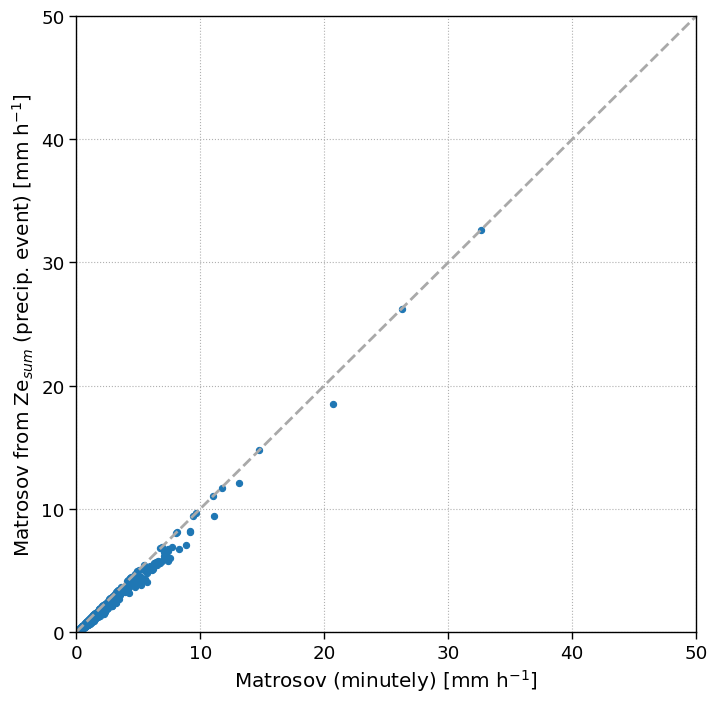

In [13]:
df_corrected.plot.scatter(x='Matrosov_a_400_mm_h', y='Matrosov_from_ze_sum_400', xlabel='Matrosov (minutely) [mm h$^{-1}$]', ylabel='Matrosov from Ze$_{sum}$ (precip. event) [mm h$^{-1}$]', figsize=(8,8), xlim=[0,50], ylim=[0,50])
x = np.linspace(0, 60, 100)
y = x
plt.plot(x, y, linestyle='--', color='darkgrey')
plt.grid(True, ls=':')

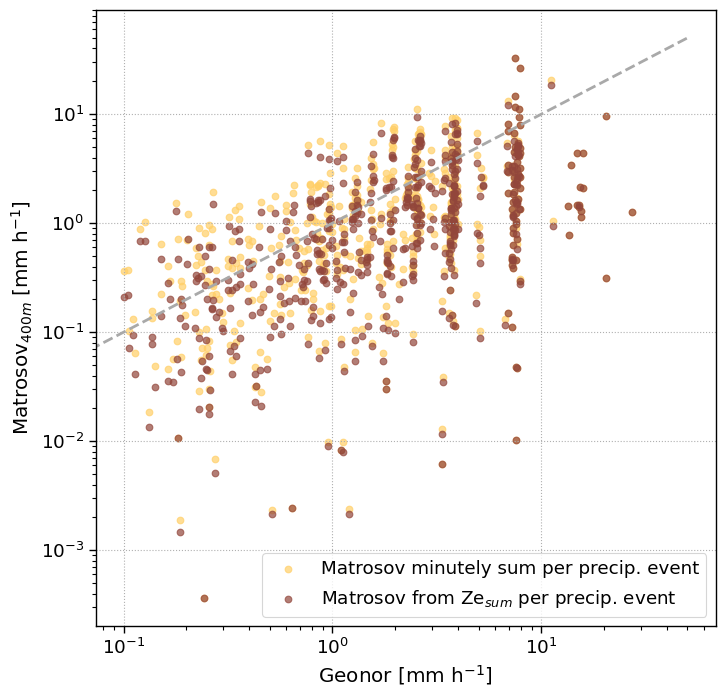

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8, ), sharex=True, sharey=True)

ax.scatter(df_corrected['rate_mm_h'], df_corrected['Matrosov_a_400_mm_h'], color=fct.cmap(0), alpha=0.7, 
           label='Matrosov minutely sum per precip. event', edgecolor=fct.cmap(0))
ax.scatter(df_corrected['rate_mm_h'], df_corrected['Matrosov_from_ze_sum_400'], color=fct.cmap(2), alpha=0.7, 
           label='Matrosov from Ze$_{sum}$ per precip. event', edgecolor=fct.cmap(2))


ax.set_xscale('log')
ax.set_yscale('log')
x = np.linspace(0, 50, 100)
y = x
ax.plot(x, y, linestyle='--', color='darkgrey')

ax.set(xlabel='Geonor [mm h$^{-1}$]', ylabel='Matrosov$_{400m}$ [mm h$^{-1}$]', )#ylim=(0, 10), xlim=(0.,10), )

ax.legend()

ax.grid(True, ls=':')


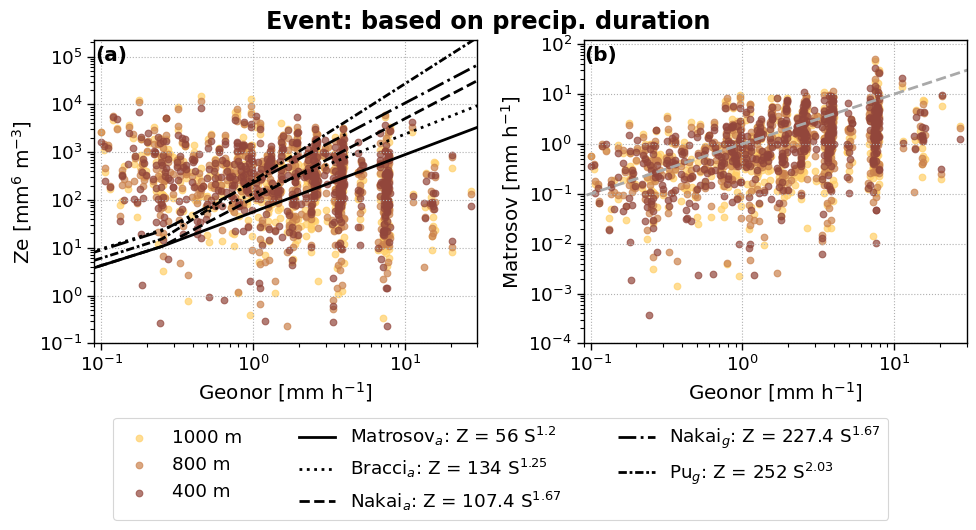

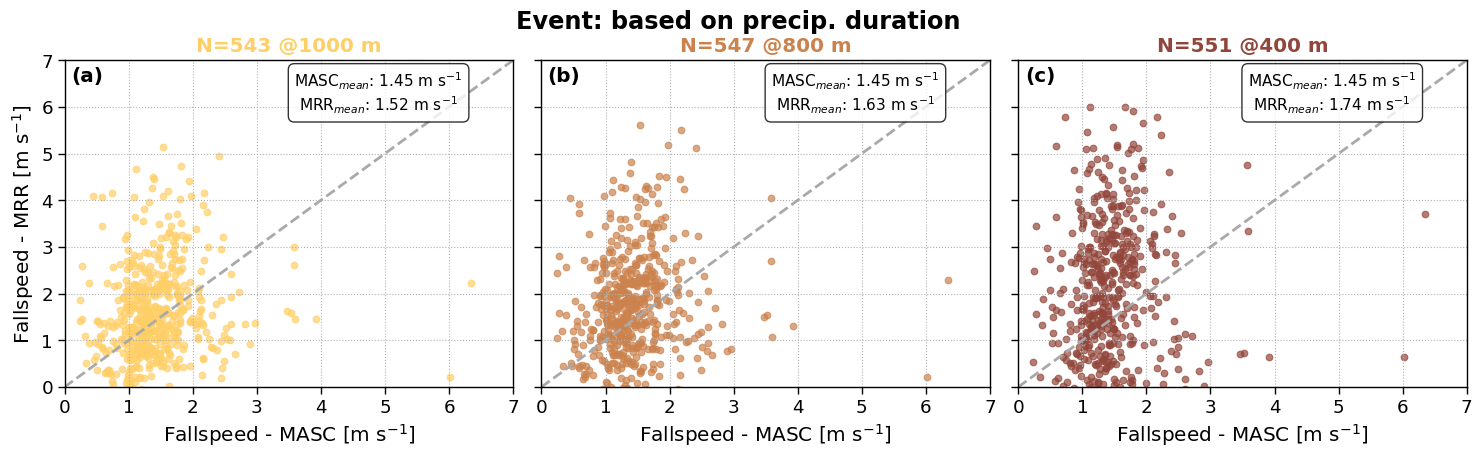

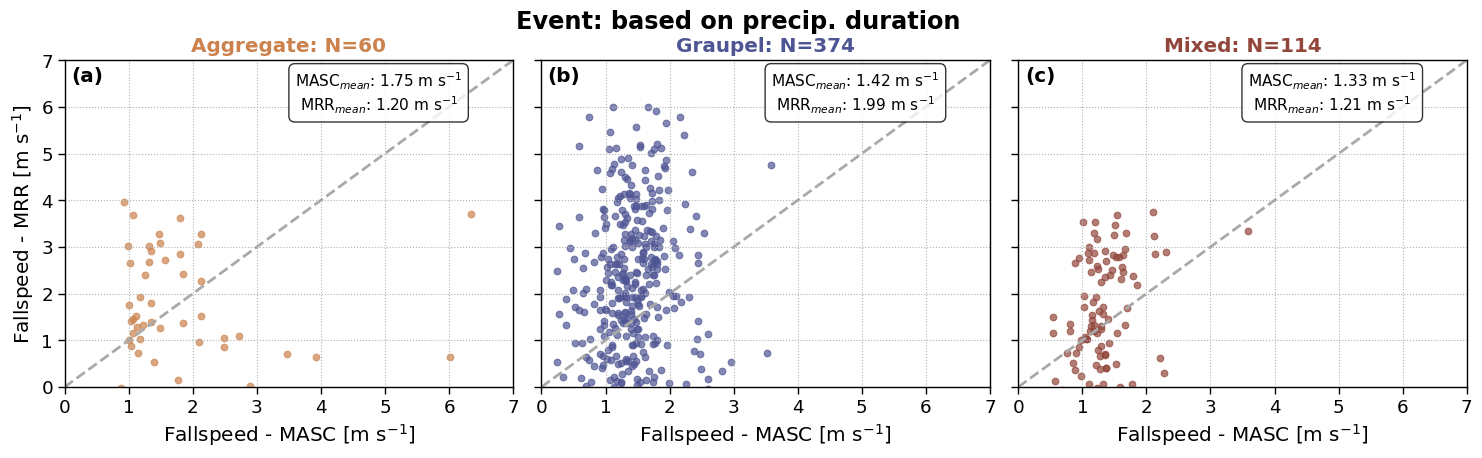

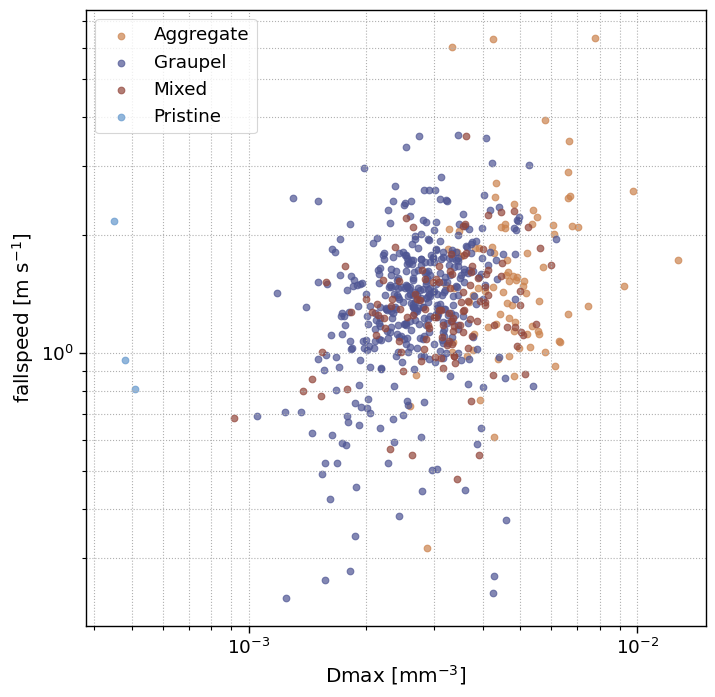

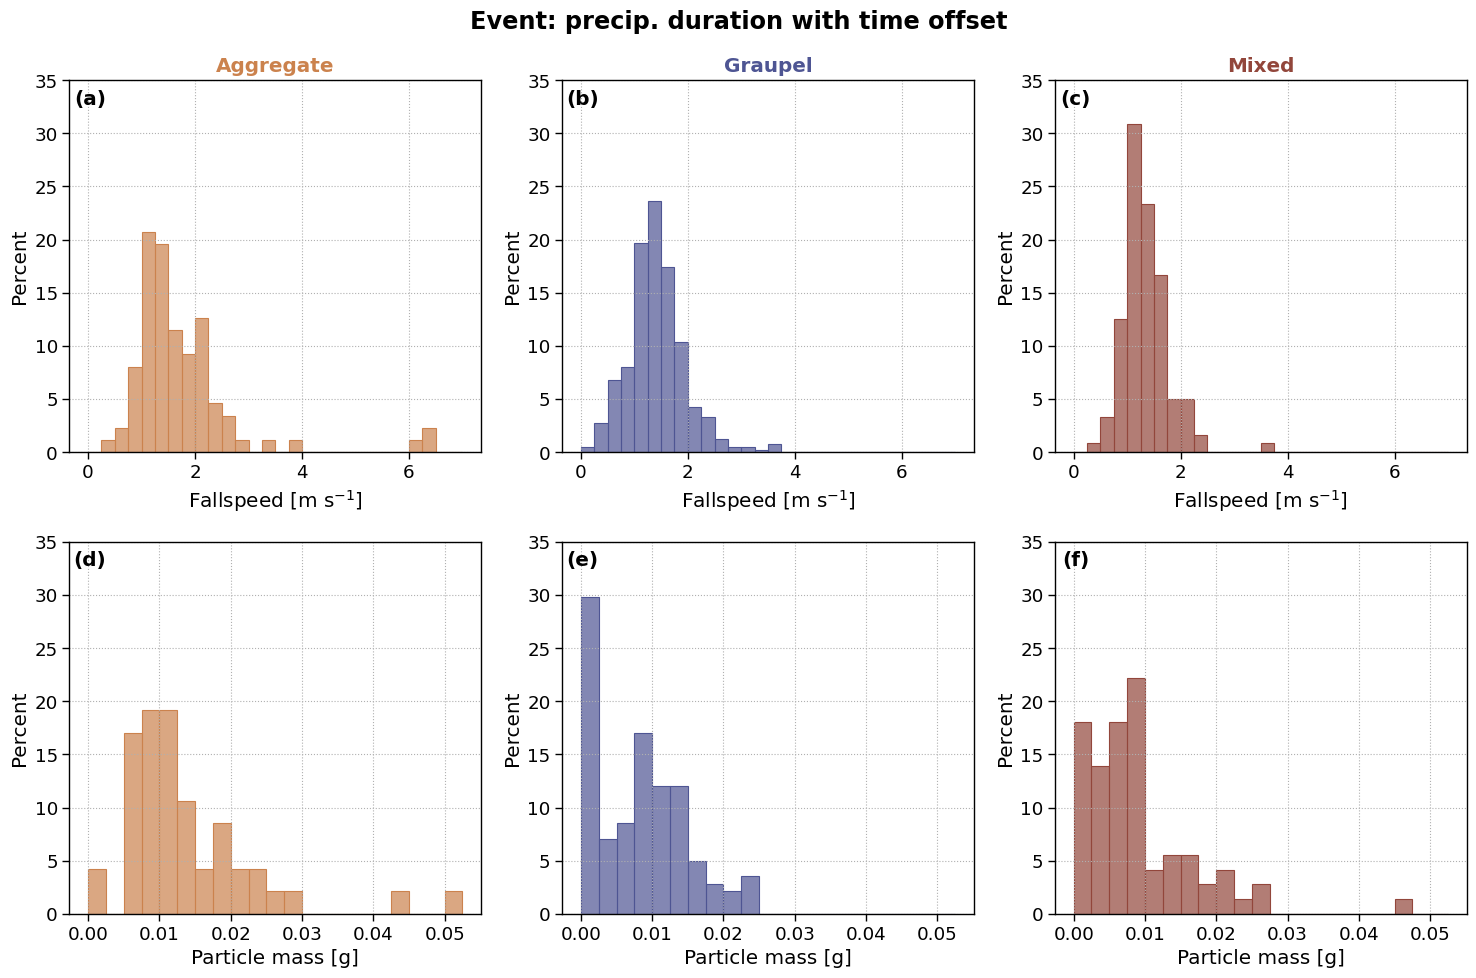

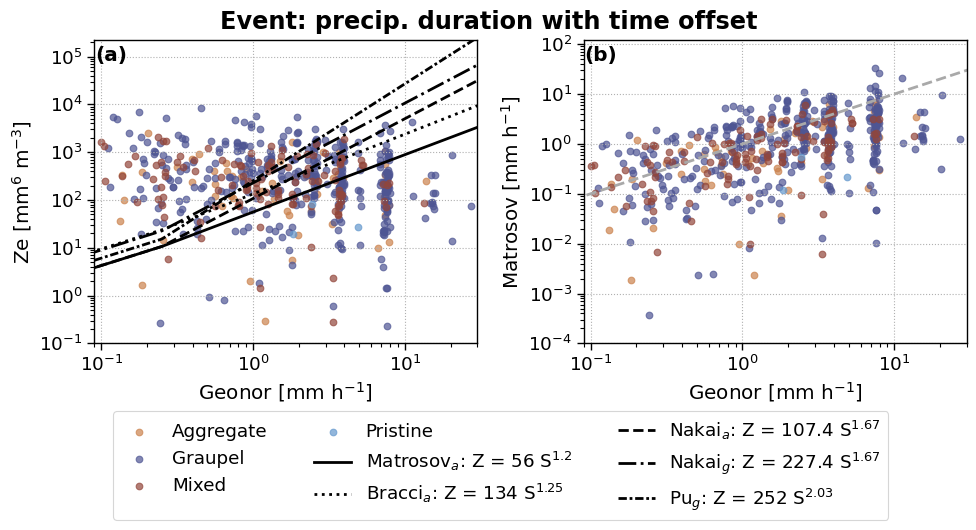

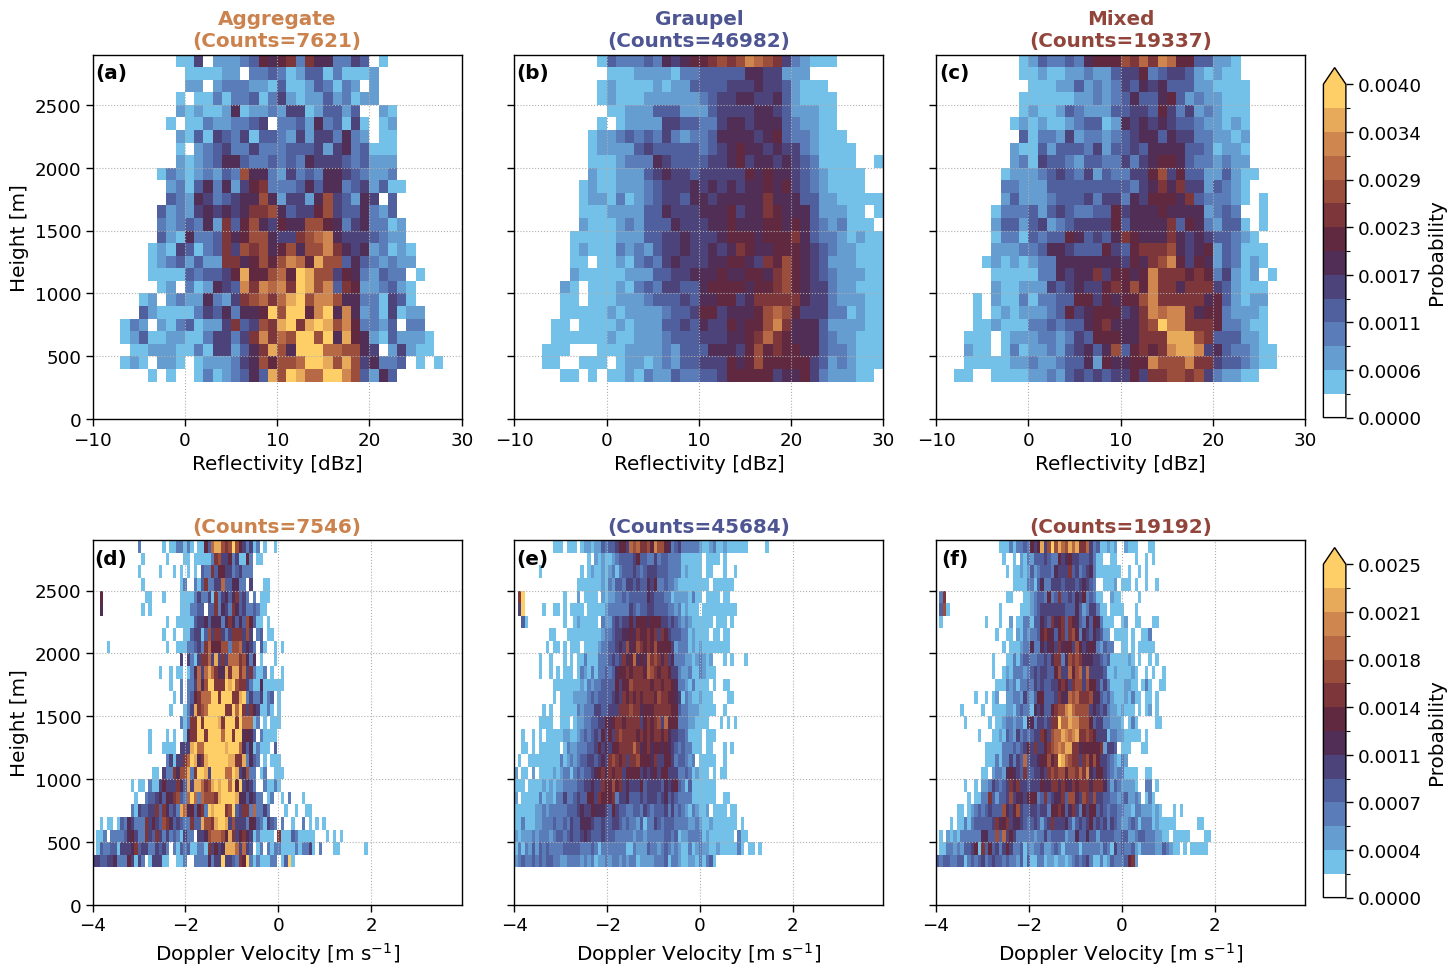

In [15]:
fct.plt_geonor_vs_ze_vs_precip_scatter(ylabels= ['Ze [mm${^6}$ m$^{-3}]$', 'Matrosov [mm h$^{-1}$]'], class_based=False, df=df_corrected, xlim=[0.09, 30],  ylim_panel0=[0.1, 220000], ylim_panel1=[0.0001, 120], title="Event: based on precip. duration")
# ------

fct.plt_masc_vs_mrr_fallspeed(class_based=False, df=df_corrected, df_only_class=None, panel_keys=[1000, 800, 400], xlim=(0.,7), ylim=(0., 7), title="Event: based on precip. duration")
# ------


only_class = dict()
ds_precip_event = dict()
H_ze = dict()
H_ze_prob = dict()
H_w = dict()
H_w_prob = dict()
for class_name in ['aggregate', 'graupel', 'mixed', 'pristine']:
    only_class[class_name] = df_corrected[df_corrected['snowflake_class_name'] == class_name]
    
    ds_precip_event[class_name] = fct.get_ds_in_precip_event(only_class[class_name], ds_23)

    H_ze[f'{class_name}'], H_ze_prob[f'{class_name}'] = fct.probability_distribution(ds_precip_event[f'{class_name}'], 'Ze', 'height', fct.ze_bins, fct.height_bins,)
    H_w[f'{class_name}'], H_w_prob[f'{class_name}'] = fct.probability_distribution(ds_precip_event[f'{class_name}'], 'W', 'height', fct.W_bins, fct.height_bins,)

fct.plt_masc_vs_mrr_fallspeed(class_based=True, df_only_class=only_class, panel_keys=['aggregate', 'graupel', 'mixed'], altitude_for_classes=400, xlim=(0.0, 7.0), ylim=(0.0, 7.0), title="Event: based on precip. duration")
# ------


fig, axsm = plt.subplots(1, 1, figsize=(8, 8, ), sharex=True, )
for (class_name, color) in fct.custom_colors.items():
    axsm.scatter(only_class[class_name]['flake_Dmax'], only_class[class_name]['fallspeed'], color=color, alpha=0.7, label=f'{class_name}'.title(), edgecolor=color)

axsm.grid(True,which='both', ls=':')
axsm.set_xscale('log')
axsm.set_yscale('log')

axsm.set(xlabel='Dmax [mm$^{-3}$]', ylabel='fallspeed [m s$^{-1}$]',  )
axsm.legend()
# ------


fct.plt_fallspeed_distribution_by_class(only_class, binrange_v=[0,7], binwidth=0.25,binrange_m=[0, 0.0525], stat='percent', title="Event: precip. duration with time offset")
# ------


fct.plt_geonor_vs_ze_vs_precip_scatter(ylabels = ['Ze [mm${^6}$ m$^{-3}]$', 'Matrosov [mm h$^{-1}$]'], class_based=True,  df=None, df_only_class=only_class, xlim=[0.09, 30],  ylim_panel0=[0.1, 220000], ylim_panel1=[0.0001, 120], title="Event: precip. duration with time offset")# , )
# ------

fct.plt_prob_agg_graupel_mixed(H_ze_prob, H_ze, H_w_prob, H_w)


### Apply time offset to account for falling particles

In [16]:
df_corrected_offset = fct.apply_timeoffset_to_df(df_corrected, ds_23)
df_corrected_offset.index.names = ['time']

psd_corrected_offset = psd_corrected.sel(time=df_corrected_offset.index)

datasets_to_concat = [psd_corrected_offset.mean('time')] * len(psd_corrected_offset['time'])
psd_corrected_offset_season = xr.concat(datasets_to_concat, dim="time")

psd_corrected_offset_concat = xr.concat([psd_corrected_offset, psd_corrected_offset_season], pd.Index(["dt", "seasonal_mean"], name="time_frame"))


corrected_offset = xr.merge([df_corrected_offset.to_xarray(), psd_corrected_offset_concat])

# Save to file
filename = f"Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc"
if len(corrected_offset) != 0:
    print(f"...writing file: {filename}")
    corrected_offset.to_netcdf(os.path.join(nc_dir, filename))

...writing file: Z_S_2Tm_WD_WS_class_precip_event_dt_offset_ANX_2023.nc


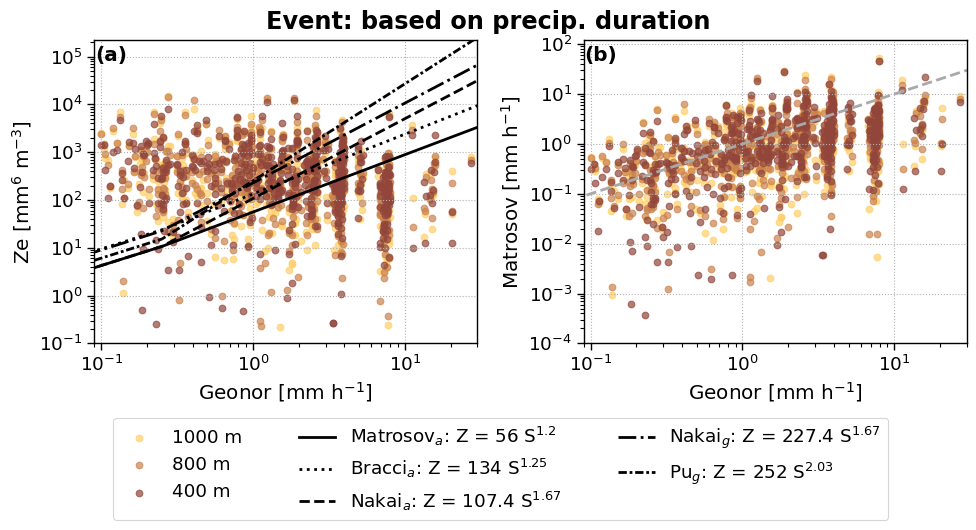

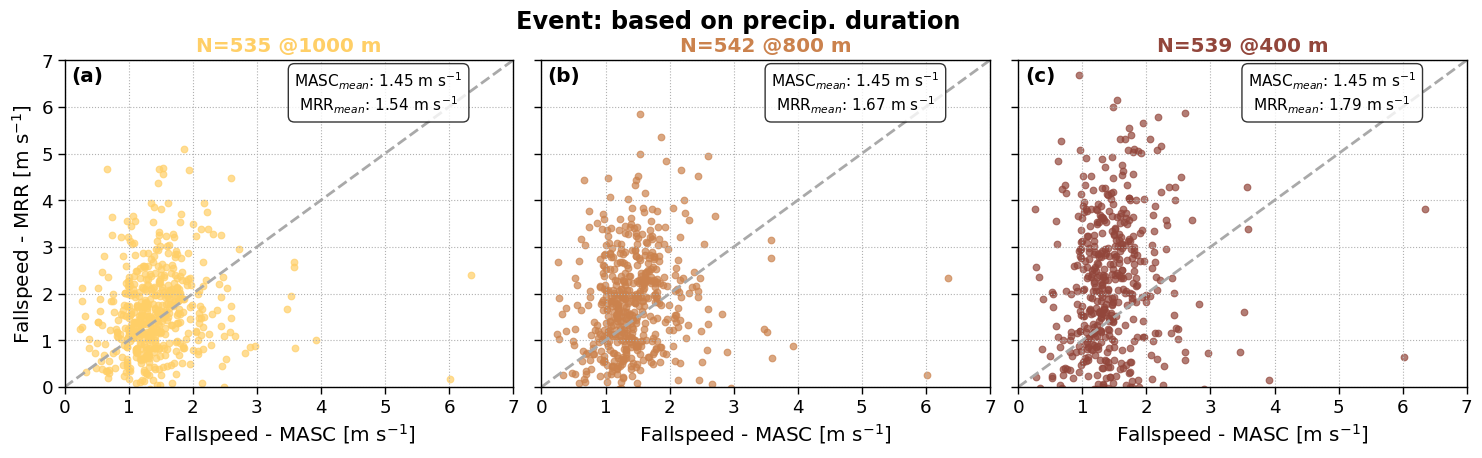

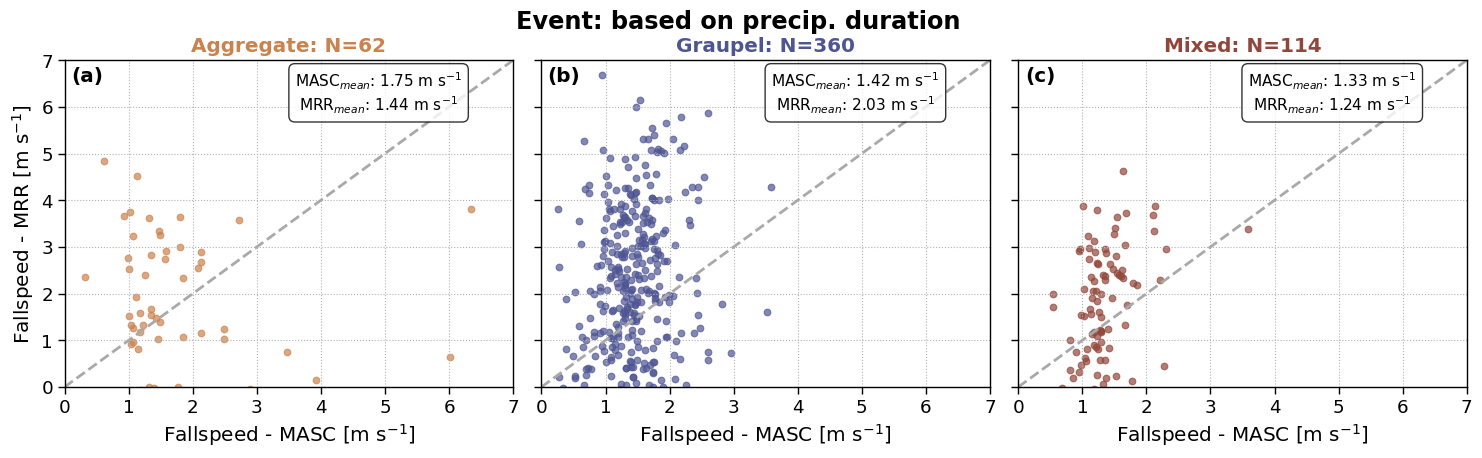

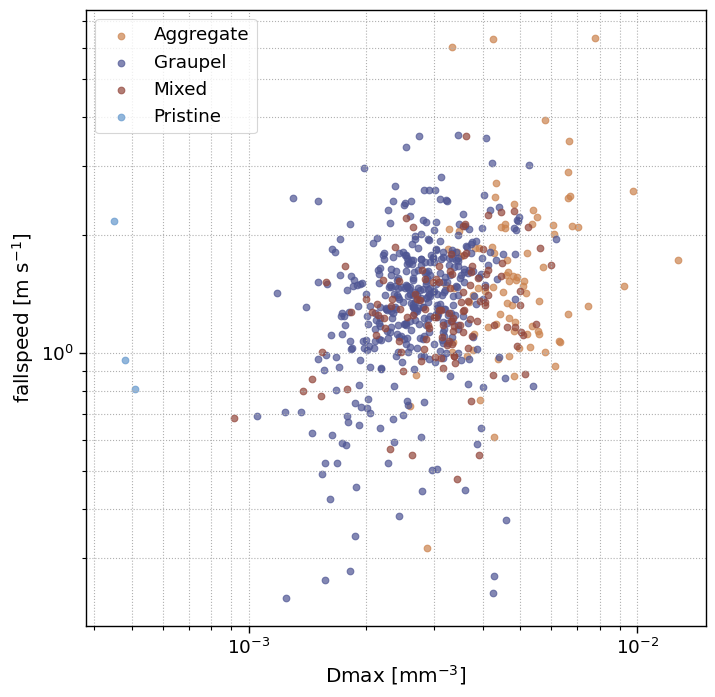

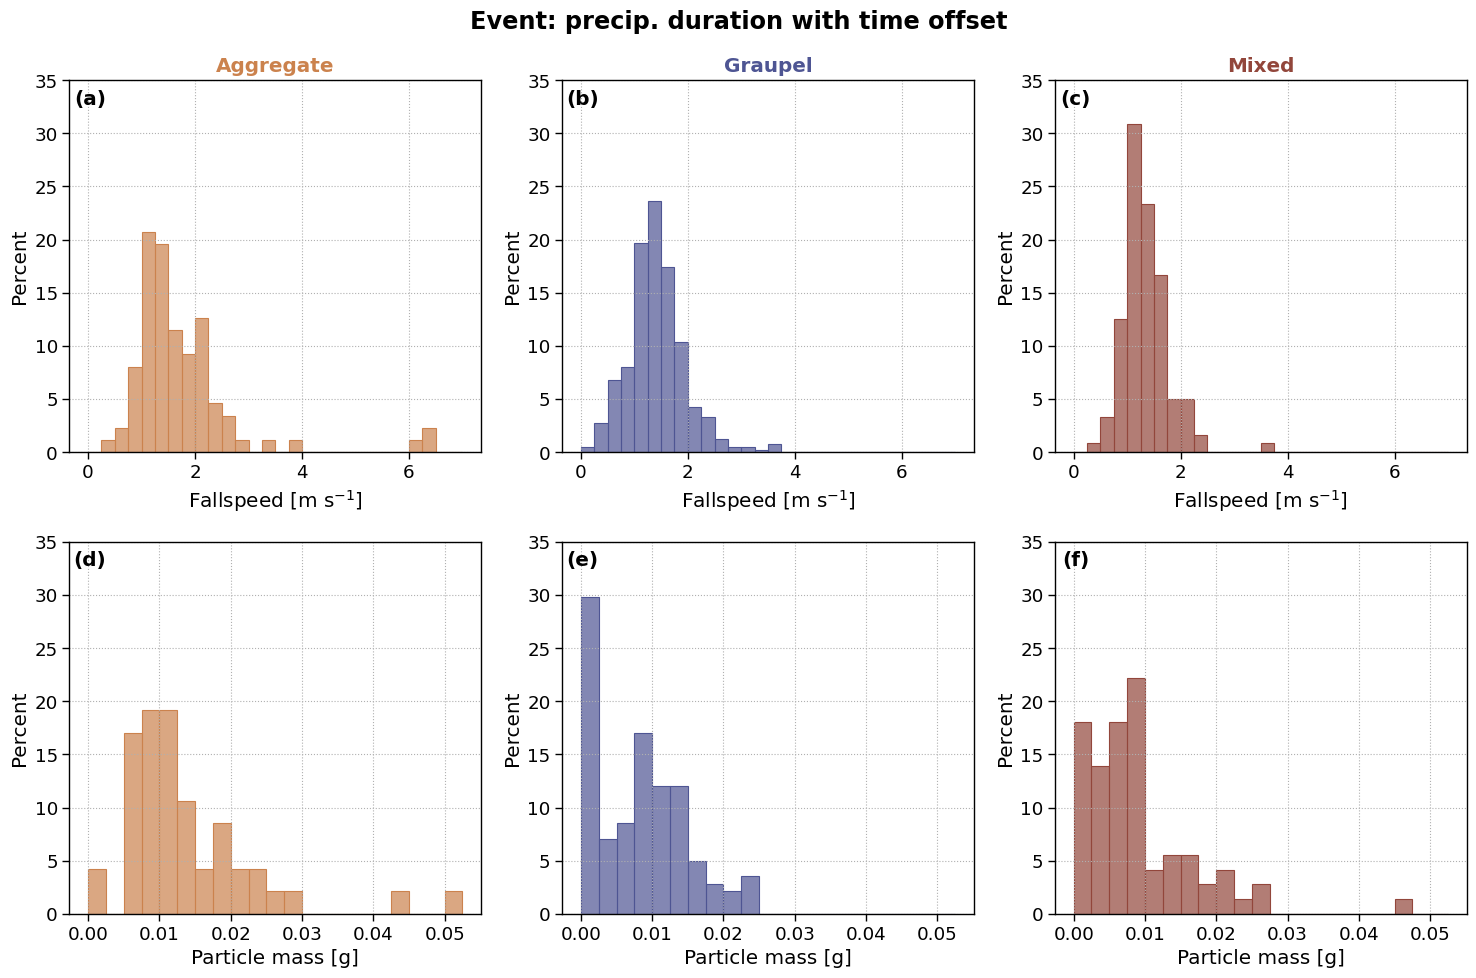

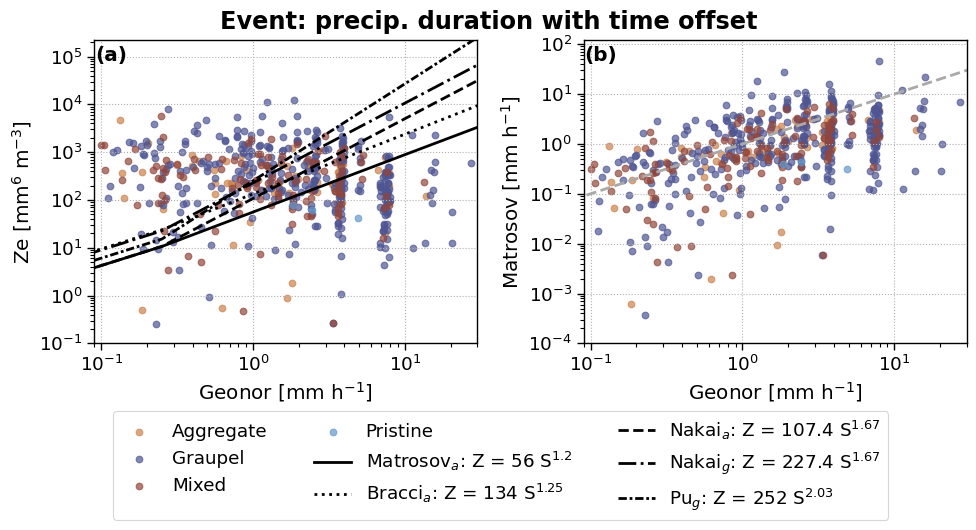

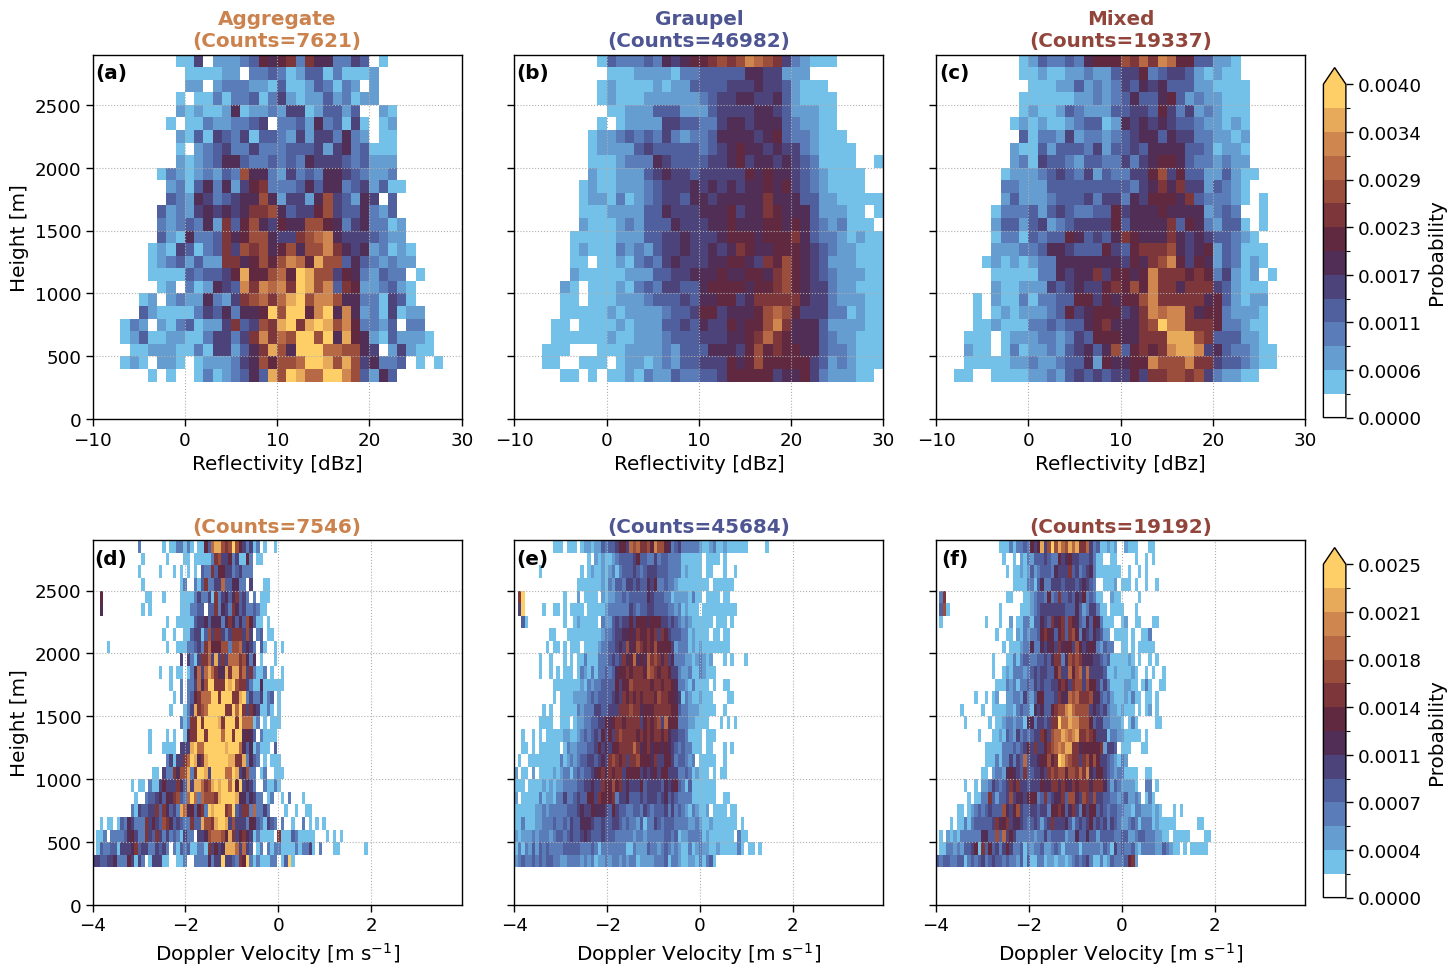

In [17]:
fct.plt_geonor_vs_ze_vs_precip_scatter(ylabels= ['Ze [mm${^6}$ m$^{-3}]$', 'Matrosov [mm h$^{-1}$]'], class_based=False, df=df_corrected_offset, xlim=[0.09, 30],  ylim_panel0=[0.1, 220000], ylim_panel1=[0.0001, 120], title="Event: based on precip. duration")
# ------

fct.plt_masc_vs_mrr_fallspeed(class_based=False, df=df_corrected_offset, df_only_class=None, panel_keys=[1000, 800, 400], xlim=(0.,7), ylim=(0., 7), title="Event: based on precip. duration")
# ------


only_class_offset = dict()
ds_offset = dict()
H_ze_offset = dict()
H_ze_offset_prob = dict()
H_w_offset = dict()
H_w_offset_prob = dict()

for class_name in ['aggregate', 'graupel', 'mixed', 'pristine']:
    only_class_offset[class_name] = df_corrected_offset[df_corrected_offset['snowflake_class_name'] == class_name]
    
    ds_offset[class_name] = fct.get_ds_in_precip_event(only_class_offset[class_name], ds_23)

    H_ze_offset[f'{class_name}'], H_ze_offset_prob[f'{class_name}'] = fct.probability_distribution(ds_offset[f'{class_name}'], 'Ze', 'height', fct.ze_bins, fct.height_bins,)

    H_w_offset[f'{class_name}'], H_w_offset_prob[f'{class_name}'] = fct.probability_distribution(ds_offset[f'{class_name}'], 'W', 'height', fct.W_bins, fct.height_bins,)

fct.plt_masc_vs_mrr_fallspeed(class_based=True, df_only_class=only_class_offset, panel_keys=['aggregate', 'graupel', 'mixed'], altitude_for_classes=400, xlim=(0.0, 7.0), ylim=(0.0, 7.0), title="Event: based on precip. duration")
# ------


fig, axsm = plt.subplots(1, 1, figsize=(8, 8, ), sharex=True, )
for (class_name, color) in fct.custom_colors.items():
    axsm.scatter(only_class_offset[class_name]['flake_Dmax'], only_class_offset[class_name]['fallspeed'], color=color, alpha=0.7, label=f'{class_name}'.title(), edgecolor=color)

axsm.grid(True,which='both', ls=':')
axsm.set_xscale('log')
axsm.set_yscale('log')

axsm.set(xlabel='Dmax [mm$^{-3}$]', ylabel='fallspeed [m s$^{-1}$]',  )
axsm.legend()
# ------


fct.plt_fallspeed_distribution_by_class(only_class_offset, binrange_v=[0,7], binwidth=0.25,binrange_m=[0, 0.0525], stat='percent', title="Event: precip. duration with time offset")
# ------


fct.plt_geonor_vs_ze_vs_precip_scatter(ylabels = ['Ze [mm${^6}$ m$^{-3}]$', 'Matrosov [mm h$^{-1}$]'], class_based=True,  df=None, df_only_class=only_class_offset, xlim=[0.09, 30],  ylim_panel0=[0.1, 220000], ylim_panel1=[0.0001, 120], title="Event: precip. duration with time offset")# , )
# ------

fct.plt_prob_agg_graupel_mixed(H_ze_offset_prob, H_ze_offset, H_w_offset_prob, H_w_offset)


In [18]:
for duration in ['1min', '5min', '10min', 
    '30min', '60min'
                 ]:

    df_corrected_duration, psd_corrected_duration = fct.process_precip_segments(df_sum, df_mean, sf_class, mode="fixed", duration=duration)
    df_corrected_duration.index.names = ['time']
    
    ### Apply time offset to account for falling particles
    df_corrected_duration_offset = fct.apply_timeoffset_to_df(df_corrected_duration, ds_23)
    df_corrected_duration_offset.index.names = ['time']

    psd_corrected_duration_offset = psd_corrected_duration.sel(time=df_corrected_duration_offset.index)

    datasets_to_concat_duration = [psd_corrected_duration_offset.mean('time')] * len(psd_corrected_duration_offset['time'])
    psd_corrected_duration_offset_season = xr.concat(datasets_to_concat_duration, dim="time")

    psd_corrected_duration_offset_concat = xr.concat([psd_corrected_duration_offset, psd_corrected_duration_offset_season], pd.Index(["dt", "seasonal_mean"], name="time_frame"))


    corrected_offset = xr.merge([df_corrected_duration_offset.to_xarray(), psd_corrected_duration_offset_concat])

    # Save to file

    filename = f"Z_S_2Tm_WD_WS_class_precip_{duration}_dt_offset_{site}_{year}.nc"
    if len(corrected_offset) != 0:
        print(f"...writing file: {filename}")
        corrected_offset.to_netcdf(os.path.join(nc_dir, filename))

...writing file: Z_S_2Tm_WD_WS_class_precip_1min_dt_offset_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_class_precip_5min_dt_offset_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_class_precip_10min_dt_offset_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_class_precip_30min_dt_offset_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_class_precip_60min_dt_offset_ANX_2023.nc


### Find the "nearest" observed crystal type when there was a reflectivity, but no crystal observation

In [19]:
test_df_sum = df_sum.copy()#.loc[slice(pd.Timestamp("2023-03-08 12:00:00"), pd.Timestamp("2023-03-09 12:00:00"))]
test_df_mean = df_mean.copy()#.loc[slice(pd.Timestamp("2023-03-08 12:00:00"), pd.Timestamp("2023-03-09 12:00:00"))]
test_sf_class = sf_class.copy()#.loc[slice(pd.Timestamp("2023-03-08 12:00:00"), pd.Timestamp("2023-03-09 12:00:00"))]


# Step 1 — round crystal timestamps to the nearest minute

test_sf_class["minute"] = test_sf_class.index.floor("T")
test_sf_class

# Step 1 — round crystal timestamps to the nearest minute

sf_groups = test_sf_class.groupby("minute")
available_minutes = pd.DatetimeIndex(list(sf_groups.groups.keys()))

# Step 2 — for each Z–S minute, find crystals


window = pd.Timedelta("15min")
assigned_rows = []    # list to accumulate results

for t in test_df_sum.index:
    if t in sf_groups.groups:
        rows = sf_groups.get_group(t)
        rows_copy = rows.copy()
        rows_copy["original_time"] = rows_copy.index
        rows_copy["assigned_time"] = t
        assigned_rows.append(rows_copy)

        
    else:
        diffs = np.abs(available_minutes - t)
        inside_window = diffs <= window
        if inside_window.any():
            # pick nearest minute that has crystals
            nearest_minute = available_minutes[inside_window][diffs[inside_window].argmin()]
            rows = sf_groups.get_group(nearest_minute)
            rows_copy = rows.copy()
            rows_copy["original_time"] = rows_copy.index
            rows_copy["assigned_time"] = t
            assigned_rows.append(rows_copy)
        
# Step 3 — combine everything
sf_assigned = pd.concat(assigned_rows, ignore_index=False)
sf_assigned = sf_assigned.set_index("assigned_time").sort_index()

In [20]:
df_ekstra_crystals, psd_ekstra_crystals = fct.process_precip_segments(test_df_sum, test_df_mean, sf_assigned, mode="event")
df_ekstra_crystals.index.names = ['time']

### Apply time offset to account for falling particles
df_ekstra_crystals_offset = fct.apply_timeoffset_to_df(df_ekstra_crystals, ds_23)
df_ekstra_crystals_offset.index.names = ['time']

psd_ekstra_crystals_offset = psd_ekstra_crystals.sel(time=df_ekstra_crystals_offset.index)

datasets_to_concat_ekstra_crystals = [psd_ekstra_crystals_offset.mean('time')] * len(psd_ekstra_crystals_offset['time'])
psd_ekstra_crystals_offset_season = xr.concat(datasets_to_concat_ekstra_crystals, dim="time")

psd_ekstra_crystals_offset_concat = xr.concat([psd_ekstra_crystals_offset, psd_ekstra_crystals_offset_season], pd.Index(["dt", "seasonal_mean"], name="time_frame"))


corrected_offset_nearby = xr.merge([df_ekstra_crystals_offset.to_xarray(), psd_ekstra_crystals_offset_concat])

# Save to file
filename = f"Z_S_2Tm_WD_WS_nearest_class_precip_event_dt_offset_{site}_{year}.nc"
if len(corrected_offset_nearby) != 0:
    print(f"...writing file: {filename}")
    corrected_offset_nearby.to_netcdf(os.path.join(nc_dir, filename))

...writing file: Z_S_2Tm_WD_WS_nearest_class_precip_event_dt_offset_ANX_2023.nc


In [21]:
for duration in ['1min', #
    '5min', '10min', '30min', 
    '60min'
                 ]:
    df_ekstra_crystals, psd_ekstra_crystals = fct.process_precip_segments(test_df_sum, test_df_mean, sf_assigned, mode="fixed", duration=duration)
    df_ekstra_crystals.index.names = ['time']
        
    ### Apply time offset to account for falling particles
    df_ekstra_crystals_offset = fct.apply_timeoffset_to_df(df_ekstra_crystals, ds_23)
    df_ekstra_crystals_offset.index.names = ['time']

    psd_ekstra_crystals_offset = psd_ekstra_crystals.sel(time=df_ekstra_crystals_offset.index)

    datasets_to_concat_ekstra_crystals = [psd_ekstra_crystals_offset.mean('time')] * len(psd_ekstra_crystals_offset['time'])
    psd_ekstra_crystals_offset_season = xr.concat(datasets_to_concat_ekstra_crystals, dim="time")

    psd_ekstra_crystals_offset_concat = xr.concat([psd_ekstra_crystals_offset, psd_ekstra_crystals_offset_season], pd.Index(["dt", "seasonal_mean"], name="time_frame"))


    corrected_offset_nearby = xr.merge([df_ekstra_crystals_offset.to_xarray(), psd_ekstra_crystals_offset_concat])
    
    # Save to file
    filename = f"Z_S_2Tm_WD_WS_nearest_class_precip_{duration}_dt_offset_{site}_{year}.nc"
    if len(corrected_offset_nearby) != 0:
        print(f"...writing file: {filename}")
        corrected_offset_nearby.to_netcdf(os.path.join(nc_dir, filename))

...writing file: Z_S_2Tm_WD_WS_nearest_class_precip_1min_dt_offset_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_nearest_class_precip_5min_dt_offset_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_nearest_class_precip_10min_dt_offset_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_nearest_class_precip_30min_dt_offset_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_nearest_class_precip_60min_dt_offset_ANX_2023.nc


### Create a dataset, which has all variables and thresholds, but the MASCDB data

In [22]:
def process_precip_segments(df_sum, df_mean, #sf_class, 
                            mode="event", duration="1H", min_rate=0.1, altitudes=[400, 800, 1000]):
    if mode == "event":
        notna_idx = df_sum['precipitation'].dropna().index
        notna_idx = notna_idx.append(pd.Index([df_sum.index[-1]]))
        segment_bounds = notna_idx

    elif mode == "fixed":
        step = pd.to_timedelta(duration)
        step = int(step/pd.Timedelta(seconds=60))
        dt_idx = df_sum.index[step::step] # step in minutes
        dt_idx = dt_idx.append(pd.Index([df_sum.index[-1] + pd.Timedelta(minutes=1)]))
        segment_bounds = dt_idx
    else:
        raise ValueError("mode must be 'event' or 'fixed'")
    
    # Loop over segments
    sums, means, sclass, mascdb, counts, zs_counts = [], [], [], [], [], []
    dt = segment_bounds.to_series().diff().dt.total_seconds()
    for i in range(len(segment_bounds)):
        if i == 0:
            seg = df_sum[:segment_bounds[0]]
            seg_m = df_mean[:segment_bounds[0]]
            # seg_sf = sf_class[:segment_bounds[0]]
            delta_h = dt.loc[:segment_bounds[0]]

        else:
            seg = df_sum.loc[segment_bounds[i-1] + pd.Timedelta(seconds=1) : segment_bounds[i]]
            seg_m = df_mean.loc[segment_bounds[i-1] + pd.Timedelta(seconds=1) : segment_bounds[i]]
            # seg_sf = sf_class.loc[segment_bounds[i-1] + pd.Timedelta(seconds=1) : segment_bounds[i]]
            delta_h = dt.loc[segment_bounds[i-1] + pd.Timedelta(seconds=1) : segment_bounds[i]]

        # filter: remove warm segments (>2 °C)
        all_T = seg_m['air_temperature'].dropna()
        if (len(all_T) != 0) and (sum(all_T > 2.) >=1):
            seg[:] = np.nan
            seg_m[:] = np.nan
            # seg_sf[:] = np.nan

        sums.append(seg.sum(numeric_only=True, min_count=1))
        means.append(seg_m.mean(numeric_only=True, skipna=True))
        # mascdb.append(seg_sf[['fallspeed', 'flake_Dmax', 'gan3d_mass']].mean(numeric_only=True, skipna=True))
        # ma_cc = seg_sf[['flake_Dmax', 'fallspeed', 'gan3d_mass']].count()
        # ma_cc = ma_cc.rename({"flake_Dmax":"count_flake_Dmax", "fallspeed":"count_fallspeed", "gan3d_mass":"count_gan3d_mass"})
        # counts.append(ma_cc)
        zs_cc = seg[['precipitation','Ze_linear_sum_400', 'Ze_linear_sum_800', 'Ze_linear_sum_1000'
                     ]].count()
        zs_cc = zs_cc.rename({"precipitation":"count_precip", "Ze_linear_sum_400":"count_Ze_lin_400", "Ze_linear_sum_800":"count_Ze_lin_800", "Ze_linear_sum_1000":"count_Ze_lin_1000"
                              })
        zs_counts.append(zs_cc)
        

        # if len(seg_sf) != 0:
        #     sclass = test_and_return_dominant_sf_class(seg_sf['snowflake_class_name'], sclass)
        #     if i== 0:
        #         psd = find_psd_in_timestep(seg_sf, delta_h, index=segment_bounds[i])
        #     else:
        #         ds_psd = find_psd_in_timestep(seg_sf, delta_h, index=segment_bounds[i])
        #         psd = xr.concat([psd, ds_psd], dim="time")

        # else:
        #     sclass.append(np.nan)
        #     if i== 0:
        #         psd = find_psd_in_timestep(seg_sf, delta_h, index=segment_bounds[i])
        #     else:
        #         ds_psd = find_psd_in_timestep(seg_sf, delta_h, index=segment_bounds[i])
        #         psd = xr.concat([psd, ds_psd], dim="time")
            

        
    # Combine into one Dataframe with all values
    df_out = pd.concat([pd.DataFrame(sums).set_index(segment_bounds),
                        pd.DataFrame(means).set_index(segment_bounds),
                        # pd.DataFrame({"snowflake_class_name":sclass}).set_index(segment_bounds), 
                        # pd.DataFrame(mascdb).set_index(segment_bounds),
                        # pd.DataFrame(counts).set_index(segment_bounds),
                        pd.DataFrame(zs_counts).set_index(segment_bounds)
                        # pd.DataFrame({"Dmax":dm}).set_index(segment_bounds),
                        # pd.DataFrame({"particle_mass":mass}).set_index(segment_bounds),
                        ], axis=1)
    df_out.rename(columns={"precipitation":"Geonor",}, inplace=True)

    # Convert snowfall increments to rate (mm/h)
    df_out["delta_h"] = df_out.index.to_series().diff().dt.total_seconds() / 3600 # Calculate time difference in hours
    df_out["rate_mm_h"] = df_out["Geonor"] / df_out["delta_h"] # Convert to mm/h rate
    df_out[df_out["rate_mm_h"] < min_rate] = np.nan # limit Geonor precipitation to be above 0.1 mm/h
    df_out['start_time'] = df_out.index - pd.to_timedelta(df_out['delta_h'] * 3600, unit='sec')

    for alt in altitudes:
        # Z from linear sums/means
        df_out[f'Z_from_linear_sum_{alt}'] = df_out[f'Ze_linear_sum_{alt}'].apply(lambda y: 10 * np.log10(y) if y > 0 else np.nan)
        df_out[f'Z_from_linear_mean_{alt}'] = df_out[f'Ze_linear_mean_{alt}'].apply(lambda y: 10 * np.log10(y) if y > 0 else np.nan)
        # Rates
        for name in ["Matrosov_a", "Bracci_a", "Nakai_a", "Nakai_g", "Pu_g"]:
            df_out[f"{name}_{alt}_mm_h"] = df_out[f"{name}_{alt}"] / df_out["delta_h"]

        # Matrosov from Ze_sum
        df_out[f'Matrosov_from_ze_sum_{alt}'] = ((df_out[f'Ze_linear_sum_{alt}'] / 56) ** (1/1.2)) /(60*df_out["delta_h"])  # convert rate to mm

    df_out.index.name = 'time'
    # ds_out = xr.concat([df_out.to_xarray(), psd], "time")
    
    # in addition in the dataframe fallspeed has to be present to adjust for the timing for the reflectivity
    # df_out = df_out[df_out['fallspeed'].notna()]
    df_out.index

    # psd = psd.sel(time=df_out.index)

    return df_out#, psd

In [23]:
for duration in ['1min', #
    '5min', '10min', '30min', 
    '60min'
                 ]:
    df_no_sf_class = process_precip_segments(df_sum, df_mean,  mode="fixed", duration=duration)
    df_no_sf_class.index.names = ['time']


    # Save to file
    filename = f"Z_S_2Tm_WD_WS_precip_{duration}_dt_{site}_{year}.nc"
    if len(df_no_sf_class) != 0:
        print(f"...writing file: {filename}")
        (df_no_sf_class.to_xarray()).to_netcdf(os.path.join(nc_dir, filename))

...writing file: Z_S_2Tm_WD_WS_precip_1min_dt_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_precip_5min_dt_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_precip_10min_dt_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_precip_30min_dt_ANX_2023.nc
...writing file: Z_S_2Tm_WD_WS_precip_60min_dt_ANX_2023.nc


In [24]:
df_no_sf_class = process_precip_segments(df_sum, df_mean,  mode="event", )
df_no_sf_class.index.names = ['time']
# Save to file
filename = f"Z_S_2Tm_WD_WS_precip_event_{site}_{year}.nc"
if len(corrected) != 0:
    print(f"...writing file: {filename}")
    (df_no_sf_class.to_xarray()).to_netcdf(os.path.join(nc_dir, filename))

...writing file: Z_S_2Tm_WD_WS_precip_event_ANX_2023.nc
